# Stage 3: DKW certificate vs number of users per class (Cor. 1), Enron, GPT-Neo 125M
**Plan:** section 4 row 3. Post-processing of Stage 2 (10 main seeds, 4 epochs); no GPU.

For each seed, m, draw and statistic: draw n users per class without replacement (200 times) and compute the DKW certificate
Ĵ_n − 2·ε(n), ε(n) = √(log(4/η)/2n), η = 0.05. **Cor. 1:** positive only if n > 8.76 / J². Compared with
n_pred = 8.76 / Ĵ²_full (full-sample Ĵ) and the predicted mean certificate Ĵ_full − 2ε(n).

Caveats: Ĵ_n is a max over thresholds, so it is biased upwards at small n; near the full sample the subsamples overlap heavily.
The aggregator uses EVAL users only (≤ 44 per class).

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import analysis as A
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
# categorical slots 1-3 (same as Stage 2); ordered groups use one blue ramp, light -> dark
COL = {"T": "#2a78d6", "S_cat": "#eb6834", "Agg": "#1baf7a"}
MRK = {"T": "o", "S_cat": "s", "Agg": "^"}
NAME = {"T": "T̂ (mean)", "S_cat": "S_cat", "Agg": "aggregator (EVAL)"}
RAMP = ["#a9cdf2", "#6aa6e8", "#2a78d6", "#174a8c"]
uv = A.S2.cached_user_values()   # Stage 2 per-user statistics (cached in Stage2/results/_user_values.csv.gz)
print(uv.groupby("run").seed.nunique().to_dict(), "models;", uv.user.nunique(), "users")

{'main': 10, 'null': 1} models; 175 users


In [2]:
cv = A.cert_vs_n(uv, m_list=[1, 8, 32])
per_seed, agg = A.summarize(cv)
display(agg[agg.m == 32].round(3))

,stat,users,m,n,seeds,mean_jhat,mean_cert,cert_min,cert_max,p_pos,pred_cert,jhat_full
14,Agg,EVAL,32,5,10,0.678,-0.646,-0.784,-0.534,0.000,-0.774,0.550
15,Agg,EVAL,32,10,10,0.625,-0.311,-0.458,-0.192,0.016,-0.386,0.550
16,Agg,EVAL,32,15,10,0.601,-0.164,-0.321,-0.034,0.112,-0.214,0.550
17,Agg,EVAL,32,20,10,0.585,-0.077,-0.239,0.066,0.262,-0.112,0.550
18,Agg,EVAL,32,25,10,0.571,-0.021,-0.198,0.119,0.496,-0.042,0.550
19,Agg,EVAL,32,30,10,0.563,0.022,-0.151,0.170,0.558,0.010,0.550
20,Agg,EVAL,32,40,6,0.505,0.037,-0.110,0.192,0.598,0.033,0.501
43,S_cat,all,32,5,10,0.700,-0.624,-0.680,-0.546,0.000,-0.785,0.539
44,S_cat,all,32,10,10,0.645,-0.291,-0.355,-0.209,0.010,-0.397,0.539
45,S_cat,all,32,15,10,0.620,-0.145,-0.210,-0.072,0.120,-0.226,0.539


## 1. Certificate vs n (m = 32)
Line: mean over seeds; band: min–max over seeds; dashed: Cor. 1 prediction Ĵ_full − 2ε(n).

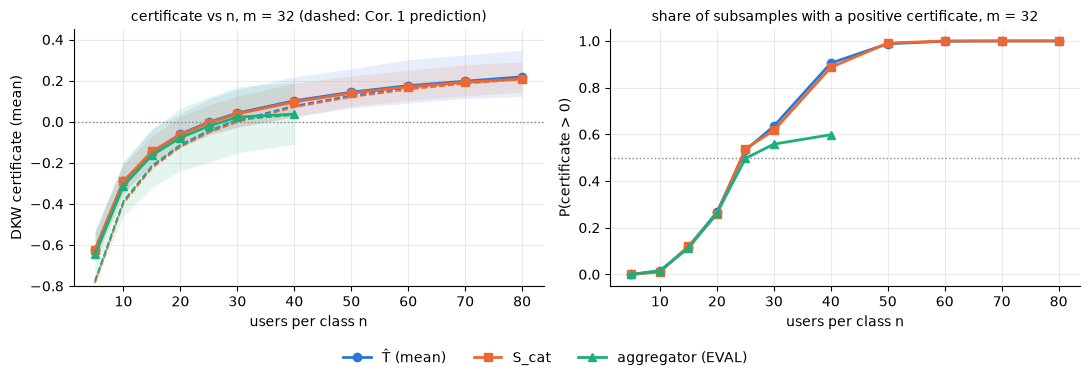

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for st in A.STATS:
    x = agg[(agg.stat == st) & (agg.m == 32)]
    axes[0].fill_between(x.n, x.cert_min, x.cert_max, color=COL[st], alpha=.12, lw=0)
    axes[0].plot(x.n, x.mean_cert, marker=MRK[st], color=COL[st], lw=2, ms=6, label=NAME[st])
    axes[0].plot(x.n, x.pred_cert, color=COL[st], lw=1.2, ls="--")
    axes[1].plot(x.n, x.p_pos, marker=MRK[st], color=COL[st], lw=2, ms=6, label=NAME[st])
axes[0].axhline(0, color="#888", lw=1, ls=":"); axes[0].set_ylim(-0.8, 0.45)
axes[0].set_xlabel("users per class n"); axes[0].set_ylabel("DKW certificate (mean)")
axes[0].set_title("certificate vs n, m = 32 (dashed: Cor. 1 prediction)", fontsize=10)
axes[1].axhline(.5, color="#888", lw=1, ls=":"); axes[1].set_xlabel("users per class n"); axes[1].set_ylabel("P(certificate > 0)")
axes[1].set_title("share of subsamples with a positive certificate, m = 32", fontsize=10)
hs, ls = axes[1].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

## 2. Users needed: empirical n₅₀ vs Cor. 1's 8.76 / Ĵ²
n₅₀ = n at which half of the subsamples give a positive certificate (interpolated); NaN = not reached with the available users.

In [4]:
nn = A.n50(per_seed)
display(nn.groupby(["stat", "m"])[["n50_empirical", "n_pred", "jhat_full", "n_max"]].agg(["mean", "min", "max"]).round(1))
display(nn[nn.m == 32].assign(ratio=lambda x: x.n50_empirical / x.n_pred).groupby("stat").ratio.describe().round(2))

n50_empirical             n_pred              jhat_full           n_max            
                  mean   min   max   mean   min    max      mean  min  max  mean   min   max
stat  m                                                                                     
Agg   1            NaN   NaN   NaN   73.7  42.4  137.6       0.4  0.3  0.5  39.8  36.0  44.0
      8           27.4  21.7  36.5   38.5  23.4   64.4       0.5  0.4  0.6  39.8  36.0  44.0
      32          25.3  17.0  38.1   33.4  17.6   74.5       0.6  0.3  0.7  39.8  36.0  44.0
S_cat 1           56.8  49.8  63.1   72.5  59.9   99.0       0.4  0.3  0.4  81.0  70.0  86.0
      8           30.9  22.1  38.7   36.4  26.0   46.3       0.5  0.4  0.6  81.0  70.0  86.0
      32          26.3  18.7  35.1   31.1  22.2   40.0       0.5  0.5  0.6  81.0  70.0  86.0
T     1           56.7  51.1  62.9   72.5  59.9   99.0       0.4  0.3  0.4  81.0  70.0  86.0
      8           30.2  21.2  37.5   34.5  23.6   43.4       0.5  0.5  0.6  81.0  70.0  86.0
      32          26.2  17.5  34.5   30.7  19.0   44.2       0.5  0.4  0.7  81.0  70.0  86.0

,count,mean,std,min,25%,50%,75%,max
stat,,,,,,,,
Agg,8.0,0.96,0.04,0.91,0.93,0.95,0.97,1.02
S_cat,10.0,0.84,0.07,0.74,0.79,0.84,0.88,0.99
T,10.0,0.86,0.06,0.78,0.80,0.87,0.89,0.94


## Notes (2026-11-25)
- **Certificate vs n (T̂, m = 32):** mean certificate −0.29 at n = 10, ≈ 0 at n = 25, +0.10 at n = 40, +0.22 at n = 80; positive in 90% of subsamples at n = 40 and ≥ 99% from n = 50. S_cat is indistinguishable from T̂; the aggregator (EVAL, ≤ 44 users) reaches only P = 0.60 at n = 40.
- **Empirical n₅₀ vs Cor. 1:** at m = 32, n₅₀ = 26.2 (17.5–34.5) vs n_pred = 8.76/Ĵ² = 30.7 (19.0–44.2); ratio 0.86 (0.78–0.94) for T̂, 0.84 for S_cat, 0.96 for the aggregator. At m = 1: 56.7 vs 72.5. Cor. 1 is slightly conservative, as expected: Ĵ_n is biased upwards at small n. The predicted mean-certificate curve Ĵ_full − 2ε(n) matches the empirical one within 0.025 for n ≥ 40.
- **Decision:** certificate behaves as Cor. 1 predicts (plan gate met). Practical reading: on Enron at m = 32, about 25–30 users per class are needed for a positive certificate at η = 0.05.